# Task 3: Sales Prediction Using Machine Learning
**Objective:** Predict Gross Sales Amount from historical retail order information.

This notebook uses the cleaned 1,000-row retail dataset from Tasks 1–2. Gross Sales Amount is defined as `Quantity × Unit Price (INR)`. To avoid a tautological model, Quantity and Unit Price are excluded from model predictors. The split is chronological (earliest 80% for training, latest 20% for testing), which is more appropriate for time-dependent sales data than a random split.

In [4]:
# If running in Google Colab, upload cleaned_retail_orders(1).csv or mount Drive, then set DATA_PATH accordingly.
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
DATA_PATH = '/content/drive/MyDrive/WeIntern/Task2/cleaned_retail_orders.csv'
df = pd.read_csv(DATA_PATH)
print('Original shape:', df.shape)
display(df.head())
display(df.dtypes)

Original shape: (1000, 17)


,Order ID,Customer Name,Gender,Age,City,Product Category,Quantity,Unit Price (INR),Discount %,Payment Method,Order Date,Customer Rating,Coupon Code,Coupon Code Clean,Customer Name Clean,City Clean,Discount Clean
0,ORD1392,Customer 147,Female,32.0,Bengaluru,Furniture,2,1042.10,0.0,Cash on Delivery,2025-02-25,2.0,NaN,NO COUPON RECORDED,Customer 147,Bengaluru,0.0
1,ORD1976,Customer 39,Female,13.0,Mumbai,Groceries,7,715.80,10.0,Credit Card,2025-09-25,2.0,SAVE10,SAVE10,Customer 39,Mumbai,10.0
2,ORD1457,Customer 253,Male,37.0,Delhi,Electronics,7,787.70,20.0,Credit Card,2025-09-29,4.0,NaN,NO COUPON RECORDED,Customer 253,Delhi,20.0
3,ORD1239,Customer 251,Male,35.0,Hyderabad,Clothing,7,1223.53,0.0,Credit Card,2025-05-12,1.0,NaN,NO COUPON RECORDED,Customer 251,Hyderabad,0.0
4,ORD1440,Customer 389,Female,42.0,Bengaluru,Electronics,1,1112.13,20.0,Debit Card,2025-03-13,2.0,NaN,NO COUPON RECORDED,Customer 389,Bengaluru,20.0


,0
Order ID,object
Customer Name,object
Gender,object
Age,float64
City,object
Product Category,object
Quantity,int64
Unit Price (INR),float64
Discount %,float64
Payment Method,object


In [5]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Explore and prepare data
Convert dates/numeric fields, calculate the target, and remove rows without a valid date or target. Missing predictors are imputed inside the modelling pipeline to avoid fitting imputers on test data.

In [6]:
df['Order Date'] = pd.to_datetime(df['Order Date'], errors='coerce')
df['Quantity'] = pd.to_numeric(df['Quantity'], errors='coerce')
df['Unit Price (INR)'] = pd.to_numeric(df['Unit Price (INR)'], errors='coerce')
df['Gross Sales Amount'] = df['Quantity'] * df['Unit Price (INR)']
for c in ['Age', 'Customer Rating', 'Discount Clean']:
    df[c] = pd.to_numeric(df[c], errors='coerce')
print('Missing values before date/target filtering:')
display(df.isna().sum().sort_values(ascending=False).to_frame('Missing count'))
df = df[df['Order Date'].notna() & df['Gross Sales Amount'].notna()].copy()
df = df.sort_values(['Order Date', 'Order ID']).reset_index(drop=True)
print('Rows available for modelling:', len(df))
print('Target summary:')
display(df['Gross Sales Amount'].describe().to_frame())

Missing values before date/target filtering:


,Missing count
Coupon Code,880
Customer Rating,261
Discount %,97
Discount Clean,97
Payment Method,65
Gender,43
Customer Name,36
Order Date,29
City,29
Order ID,0


Rows available for modelling: 971
Target summary:


,Gross Sales Amount
count,9.710000e+02
mean,3.107036e+04
std,2.660689e+05
min,1.983400e+02
25%,1.759935e+03
50%,3.809640e+03
75%,7.723810e+03
max,4.000000e+06


## 2. Feature engineering
Extract calendar features from Order Date. Lag and rolling-average features use only earlier rows (`shift(1)`), so the current target is never included in its own predictors.

In [7]:
df['year'] = df['Order Date'].dt.year
df['month'] = df['Order Date'].dt.month
df['quarter'] = df['Order Date'].dt.quarter
df['day_of_week'] = df['Order Date'].dt.dayofweek
df['day_of_month'] = df['Order Date'].dt.day
df['is_weekend'] = (df['day_of_week'] >= 5).astype(int)
df['sales_lag_1'] = df['Gross Sales Amount'].shift(1)
df['sales_lag_7'] = df['Gross Sales Amount'].shift(7)
df['sales_rolling_mean_7'] = df['Gross Sales Amount'].shift(1).rolling(7, min_periods=1).mean()
df['sales_rolling_mean_30'] = df['Gross Sales Amount'].shift(1).rolling(30, min_periods=1).mean()
features = ['Gender','Age','City Clean','Product Category','Discount Clean','Payment Method','Customer Rating',
            'year','month','quarter','day_of_week','day_of_month','is_weekend',
            'sales_lag_1','sales_lag_7','sales_rolling_mean_7','sales_rolling_mean_30']
target = 'Gross Sales Amount'
X, y = df[features].copy(), df[target].astype(float)
print('Feature count:', len(features))
print('Excluded direct target drivers: Quantity, Unit Price (INR); excluded identifiers/free text: Order ID, customer name, coupon code.')

Feature count: 17
Excluded direct target drivers: Quantity, Unit Price (INR); excluded identifiers/free text: Order ID, customer name, coupon code.


## 3. Chronological 80/20 split and preprocessing
Categorical columns are one-hot encoded. Numeric missing values are replaced by the training median; categorical missing values by the most frequent category. Standardization is included for the linear regression baseline.

In [8]:
split_idx = int(len(df) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]
cat_cols = X.select_dtypes(include=['object','string']).columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]
preprocessor = ColumnTransformer([
 ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), num_cols),
 ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), cat_cols)
])
print(f'Train: {len(X_train)} rows ({len(X_train)/len(X):.0%}) | Test: {len(X_test)} rows ({len(X_test)/len(X):.0%}')

Train: 776 rows (80%) | Test: 195 rows (20%


## 4. Train two regression models and compare
Linear Regression is the interpretable baseline. Random Forest captures nonlinear relationships and feature interactions. RMSE penalizes large errors more strongly, MAE gives average absolute error in INR, and R² measures variance explained (it can be negative on a test set).

In [9]:
models = {
 'Linear Regression': Pipeline([('preprocess', preprocessor), ('model', LinearRegression())]),
 'Random Forest': Pipeline([('preprocess', preprocessor), ('model', RandomForestRegressor(n_estimators=250, min_samples_leaf=2, random_state=42, n_jobs=-1))])
}
results, predictions = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred
    results.append({'Model': name, 'RMSE (INR)': mean_squared_error(y_test, pred)**0.5,
                    'MAE (INR)': mean_absolute_error(y_test, pred), 'R-squared': r2_score(y_test, pred)})
comparison = pd.DataFrame(results).sort_values('RMSE (INR)')
display(comparison.style.format({'RMSE (INR)':'{:,.2f}','MAE (INR)':'{:,.2f}','R-squared':'{:.4f}'}))

,Model,RMSE (INR),MAE (INR),R-squared
0,Linear Regression,"187,433.36","61,030.57",-0.0975
1,Random Forest,"211,334.93","57,326.56",-0.3953


## 5. Tune Random Forest using RandomizedSearchCV
TimeSeriesSplit preserves time order in validation folds. The held-out final 20% is not used to choose hyperparameters.

In [10]:
rf_pipe = Pipeline([('preprocess', preprocessor), ('model', RandomForestRegressor(random_state=42, n_jobs=-1))])
param_dist = {
 'model__n_estimators':[150,250,350], 'model__max_depth':[None,6,10,16],
 'model__min_samples_split':[2,5,10], 'model__min_samples_leaf':[1,2,4],
 'model__max_features':[0.6,0.8,1.0]
}
search = RandomizedSearchCV(rf_pipe, param_distributions=param_dist, n_iter=10,
 scoring='neg_root_mean_squared_error', cv=TimeSeriesSplit(n_splits=3),
 random_state=42, n_jobs=-1, verbose=1)
search.fit(X_train, y_train)
tuned_model = search.best_estimator_
tuned_pred = tuned_model.predict(X_test)
tuned_row = {'Model':'Tuned Random Forest', 'RMSE (INR)':mean_squared_error(y_test,tuned_pred)**0.5,
             'MAE (INR)':mean_absolute_error(y_test,tuned_pred), 'R-squared':r2_score(y_test,tuned_pred)}
comparison_all = pd.concat([comparison, pd.DataFrame([tuned_row])], ignore_index=True).sort_values('RMSE (INR)')
print('Best parameters:', search.best_params_)
display(comparison_all.style.format({'RMSE (INR)':'{:,.2f}','MAE (INR)':'{:,.2f}','R-squared':'{:.4f}'}))

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best parameters: {'model__n_estimators': 350, 'model__min_samples_split': 5, 'model__min_samples_leaf': 4, 'model__max_features': 0.6, 'model__max_depth': 16}


,Model,RMSE (INR),MAE (INR),R-squared
0,Linear Regression,"187,433.36","61,030.57",-0.0975
2,Tuned Random Forest,"188,813.12","47,938.88",-0.1137
1,Random Forest,"211,334.93","57,326.56",-0.3953


## 6. Feature importance
Importance is a model-specific indicator of how much the tuned Random Forest relies on each encoded feature. It is not proof of causation.

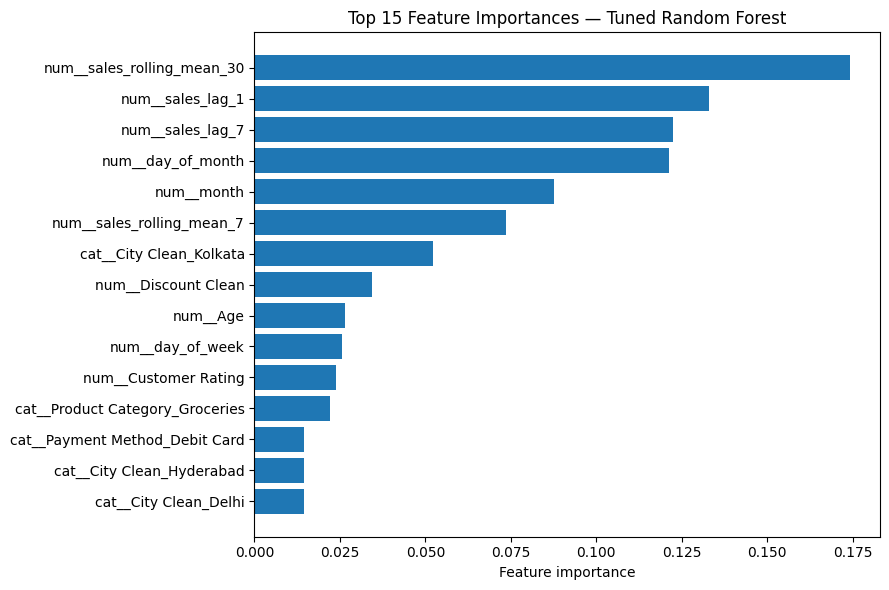

,Feature,Importance
12,num__sales_rolling_mean_30,0.174300
9,num__sales_lag_1,0.132904
10,num__sales_lag_7,0.122327
7,num__day_of_month,0.121230
4,num__month,0.087665
11,num__sales_rolling_mean_7,0.073715
19,cat__City Clean_Kolkata,0.052128
1,num__Discount Clean,0.034374
0,num__Age,0.026472
6,num__day_of_week,0.025596


In [11]:
feature_names = tuned_model.named_steps['preprocess'].get_feature_names_out()
importances = tuned_model.named_steps['model'].feature_importances_
importance_df = pd.DataFrame({'Feature':feature_names, 'Importance':importances}).sort_values('Importance', ascending=False).head(15)
plt.figure(figsize=(9,6)); plt.barh(importance_df.sort_values('Importance')['Feature'], importance_df.sort_values('Importance')['Importance'])
plt.xlabel('Feature importance'); plt.title('Top 15 Feature Importances — Tuned Random Forest'); plt.tight_layout(); plt.show()
display(importance_df)

## 7. Actual vs predicted and residual checks

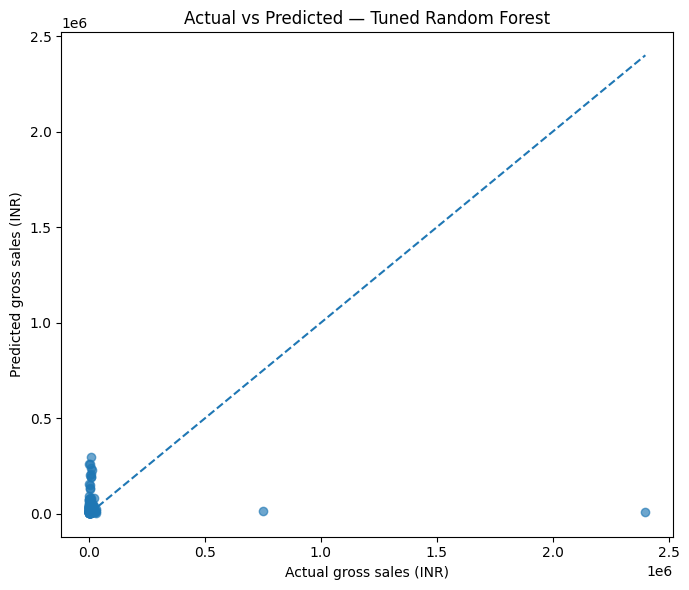

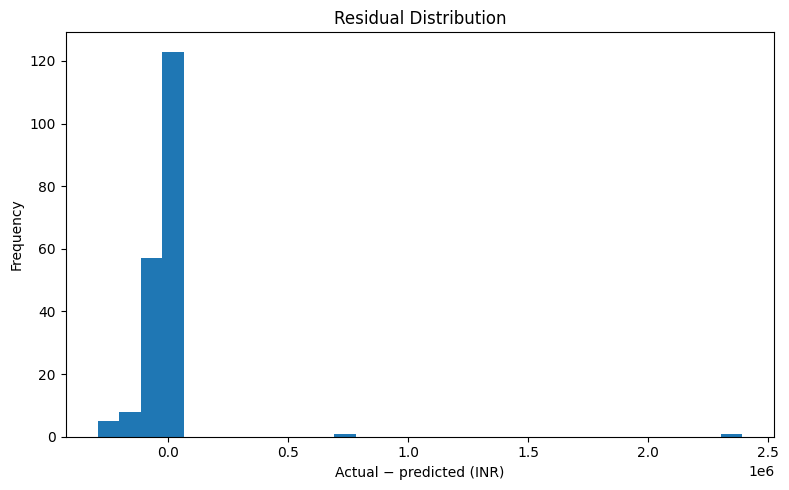

Mean residual (INR): -14819.61
Median absolute error (INR): 14711.96


In [12]:
plt.figure(figsize=(7,6)); plt.scatter(y_test, tuned_pred, alpha=.65)
lim = max(float(y_test.max()), float(np.max(tuned_pred)))
plt.plot([0,lim],[0,lim], linestyle='--'); plt.xlabel('Actual gross sales (INR)'); plt.ylabel('Predicted gross sales (INR)')
plt.title('Actual vs Predicted — Tuned Random Forest'); plt.tight_layout(); plt.show()
residuals = y_test.to_numpy() - tuned_pred
plt.figure(figsize=(8,5)); plt.hist(residuals, bins=30); plt.xlabel('Actual − predicted (INR)'); plt.ylabel('Frequency')
plt.title('Residual Distribution'); plt.tight_layout(); plt.show()
print('Mean residual (INR):', round(float(np.mean(residuals)),2))
print('Median absolute error (INR):', round(float(np.median(np.abs(residuals))),2))

## 8. Business interpretation, limitations, and conclusion
- The model estimates transaction gross sales from calendar, customer/order attributes, discount, and past-sales information.
- Compare RMSE and MAE in INR with typical transaction values; R² close to 1 is stronger, while a negative R² means worse than predicting the test-set mean.
- Quantity and Unit Price are deliberately excluded because the target is mathematically derived from them. If those values are known at order creation, a direct calculation is preferable to ML; if the business goal is to forecast sales before order details exist, this feature set is more relevant.
- Lag features assume earlier transaction outcomes are available at prediction time and records are sorted chronologically. For genuine daily forecasting, aggregate orders by date and validate on later dates.
- The dataset covers one year and has missing values and extreme sales values. Performance may not generalize to other periods or stores. Feature importance is predictive, not causal.
- Do not claim that the model is production-ready; test with additional future data and monitor errors.